# 03 Statistical Testing
Run assumption-aware numeric and categorical association tests with effect sizes and FDR correction.

In [11]:
from pathlib import Path
import sys
from typing import Any, cast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.feature_selection import mutual_info_classif

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw_data

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_columns = ["gender", "SeniorCitizen", "Partner", "Dependents", "InternetService", "Contract", "PaymentMethod", "TechSupport"]
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [12]:
# Normality is assessed separately from linearity. A non-normal feature can still have a linear or monotonic relationship with churn.
normality_rows = []
for feature in numeric_columns:
    values = data[feature].dropna()
    shapiro_sample = values.sample(min(len(values), 500), random_state=42)
    shapiro_result = cast(Any, stats.shapiro(shapiro_sample))
    dagostino_result = cast(Any, stats.normaltest(values))
    anderson_result = cast(Any, stats.anderson(values))
    normality_rows.append({
        "feature": feature,
        "n": len(values),
        "skewness": float(values.skew()),
        "kurtosis": float(values.kurtosis()),
        "shapiro_w": float(shapiro_result[0]),
        "shapiro_p": float(shapiro_result[1]),
        "anderson_statistic": float(anderson_result[0]),
        "dagostino_statistic": float(dagostino_result[0]),
        "dagostino_p": float(dagostino_result[1]),
    })
normality_table = pd.DataFrame(normality_rows)
normality_table

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20640\1285365121.py:8: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson_result = cast(Any, stats.anderson(values))


,feature,n,skewness,kurtosis,shapiro_w,shapiro_p,anderson_statistic,dagostino_statistic,dagostino_p
0,tenure,7043,0.239540,-1.387372,0.898306,1.019508e-17,203.235471,76258.505174,0.000000e+00
1,MonthlyCharges,7043,-0.220524,-1.257260,0.915726,4.496143e-16,170.555235,11419.528789,0.000000e+00
2,TotalCharges,7032,0.961642,-0.231799,0.872409,8.059008e-20,345.227264,805.983441,9.614342e-176


## Test selection rationale

The numeric target comparison uses Welch's t-test when variances differ and Mann-Whitney U as a distribution-robust companion. The categorical target comparison uses chi-square independence; Fisher's exact test is used for suitable 2x2 tables when expected counts are small. P-values are paired with effect sizes and corrected with Benjamini-Hochberg FDR.

In [13]:
# Numeric feature versus churn: Welch t-test, Mann-Whitney U, Cohen's d, and rank-biserial correlation.
def classify_effect(size: Any) -> str:
    magnitude = abs(float(size))
    if magnitude < 0.10:
        return "negligible"
    if magnitude < 0.30:
        return "small"
    if magnitude < 0.50:
        return "moderate"
    return "large"

numeric_rows = []
for feature in numeric_columns:
    churned = data.loc[data["Churn"] == 1, feature].dropna().to_numpy()
    retained = data.loc[data["Churn"] == 0, feature].dropna().to_numpy()
    welch_result = cast(Any, stats.ttest_ind(churned, retained, equal_var=False))
    mann_result = cast(Any, stats.mannwhitneyu(churned, retained, alternative="two-sided"))
    welch_stat, welch_p = float(welch_result[0]), float(welch_result[1])
    mann_stat, mann_p = float(mann_result[0]), float(mann_result[1])
    pooled_sd = np.sqrt(((len(churned) - 1) * np.var(churned, ddof=1) + (len(retained) - 1) * np.var(retained, ddof=1)) / (len(churned) + len(retained) - 2))
    cohens_d = (np.mean(churned) - np.mean(retained)) / pooled_sd if pooled_sd else 0.0
    rank_biserial = 2 * mann_stat / (len(churned) * len(retained)) - 1
    numeric_rows.append({"feature": feature, "welch_t": welch_stat, "welch_p": welch_p, "mann_whitney_u": mann_stat, "mann_whitney_p": mann_p, "cohens_d": cohens_d, "rank_biserial": rank_biserial, "effect_interpretation": classify_effect(cohens_d)})
numeric_comparison = pd.DataFrame(numeric_rows)
numeric_comparison

,feature,welch_t,welch_p,mann_whitney_u,mann_whitney_p,cohens_d,rank_biserial,effect_interpretation
0,tenure,-34.823819,1.195495e-232,2515538.0,2.419636e-208,-0.852250,-0.479734,large
1,MonthlyCharges,18.407527,8.592449e-73,6003125.5,3.311628e-54,0.446283,0.241571,moderate
2,TotalCharges,-18.800768,1.152494e-75,3360665.0,1.995985e-84,-0.460773,-0.303464,moderate


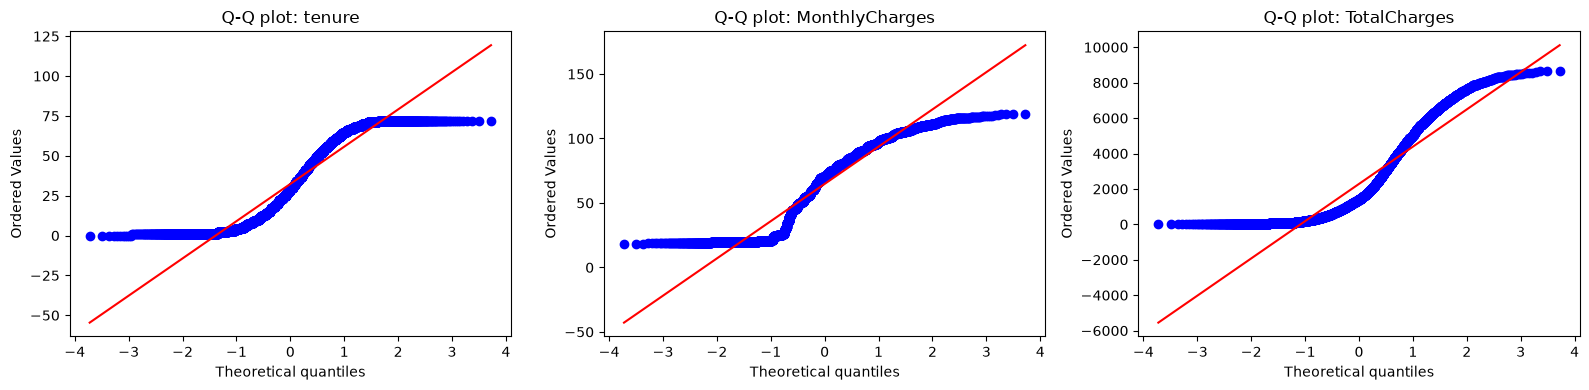

In [5]:
# Q-Q plots provide a visual normality diagnostic for each numeric feature.
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(16, 4))
for axis, feature in zip(axes, numeric_columns):
    stats.probplot(data[feature].dropna(), dist="norm", plot=axis)
    axis.set_title(f"Q-Q plot: {feature}")
plt.tight_layout()
plt.show()

In [6]:
# Categorical feature versus churn: chi-square, Cramer's V, and Fisher's exact test when appropriate.
categorical_rows = []
for feature in categorical_columns:
    contingency = pd.crosstab(data[feature], data["Churn"])
    chi2, chi_p, degrees_of_freedom, expected = stats.chi2_contingency(contingency)
    chi2 = float(chi2)
    chi_p = float(chi_p)
    sample_size = contingency.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / sample_size) if sample_size else 0.0
    fisher_p = np.nan
    test_used = "Chi-square independence"
    if contingency.shape == (2, 2) and (expected < 5).any():
        fisher_p = float(stats.fisher_exact(contingency.to_numpy())[1])
        test_used = "Fisher exact"
    categorical_rows.append({"feature": feature, "test": test_used, "chi_square": chi2, "degrees_of_freedom": degrees_of_freedom, "chi_square_p": chi_p, "fisher_p": fisher_p, "cramers_v": cramers_v, "effect_interpretation": classify_effect(cramers_v)})
categorical_comparison = pd.DataFrame(categorical_rows)
categorical_comparison

,feature,test,chi_square,degrees_of_freedom,chi_square_p,fisher_p,cramers_v,effect_interpretation
0,gender,Chi-square independence,0.484083,1,4.865787e-01,NaN,0.008291,negligible
1,SeniorCitizen,Chi-square independence,159.426300,1,1.510067e-36,NaN,0.150453,small
2,Partner,Chi-square independence,158.733382,1,2.139911e-36,NaN,0.150126,small
3,Dependents,Chi-square independence,189.129249,1,4.924922e-43,NaN,0.163870,small
4,InternetService,Chi-square independence,732.309590,2,9.571788e-160,NaN,0.322455,moderate
5,Contract,Chi-square independence,1184.596572,2,5.863038e-258,NaN,0.410116,moderate
6,PaymentMethod,Chi-square independence,648.142327,3,3.682355e-140,NaN,0.303359,moderate
7,TechSupport,Chi-square independence,828.197068,2,1.443084e-180,NaN,0.342916,moderate


In [7]:
# Apply Benjamini-Hochberg FDR correction across the planned numeric and categorical association tests.
numeric_p_values = numeric_comparison["mann_whitney_p"].to_numpy()
categorical_p_values = categorical_comparison["chi_square_p"].to_numpy()
all_p_values = np.concatenate([numeric_p_values, categorical_p_values])
all_adjusted = multipletests(all_p_values, method="fdr_bh")[1]
numeric_comparison["adjusted_p_value"] = all_adjusted[:len(numeric_p_values)]
numeric_comparison["significant_fdr_05"] = numeric_comparison["adjusted_p_value"] < 0.05
categorical_comparison["adjusted_p_value"] = all_adjusted[len(numeric_p_values):]
categorical_comparison["significant_fdr_05"] = categorical_comparison["adjusted_p_value"] < 0.05
print("FDR correction controls the expected proportion of false discoveries across the planned association tests.")
display(numeric_comparison[["feature", "mann_whitney_p", "adjusted_p_value", "cohens_d", "significant_fdr_05"]])
display(categorical_comparison[["feature", "test", "chi_square_p", "adjusted_p_value", "cramers_v", "significant_fdr_05"]])

FDR correction controls the expected proportion of false discoveries across the planned association tests.


,feature,mann_whitney_p,adjusted_p_value,cohens_d,significant_fdr_05
0,tenure,2.419636e-208,1.330800e-207,-0.852250,True
1,MonthlyCharges,3.311628e-54,5.203986e-54,0.446283,True
2,TotalCharges,1.995985e-84,3.659306e-84,-0.460773,True


,feature,test,chi_square_p,adjusted_p_value,cramers_v,significant_fdr_05
0,gender,Chi-square independence,4.865787e-01,4.865787e-01,0.008291,False
1,SeniorCitizen,Chi-square independence,1.510067e-36,1.845637e-36,0.150453,True
2,Partner,Chi-square independence,2.139911e-36,2.353902e-36,0.150126,True
3,Dependents,Chi-square independence,4.924922e-43,6.771767e-43,0.163870,True
4,InternetService,Chi-square independence,9.571788e-160,2.632242e-159,0.322455,True
5,Contract,Chi-square independence,5.863038e-258,6.449342e-257,0.410116,True
6,PaymentMethod,Chi-square independence,3.682355e-140,8.101180e-140,0.303359,True
7,TechSupport,Chi-square independence,1.443084e-180,5.291308e-180,0.342916,True


## Correlation and rank association

Pearson correlation measures linear association. Spearman correlation measures monotonic association and is less sensitive to outliers. Kendall's tau is another rank-based measure useful for small or tied samples. None of these tests establishes causality, and a Pearson/Spearman difference alone is not proof of nonlinearity.

In [8]:
# Numeric association with churn using Pearson, Spearman, and Kendall's tau.
correlation_rows = []
for feature in numeric_columns:
    values = data[[feature, "Churn"]].dropna()
    pearson_r, pearson_p = stats.pearsonr(values[feature], values["Churn"])
    spearman_r, spearman_p = stats.spearmanr(values[feature], values["Churn"] )
    kendall_tau, kendall_p = stats.kendalltau(values[feature], values["Churn"] )
    correlation_rows.append({"feature": feature, "pearson_r": pearson_r, "pearson_p": pearson_p, "spearman_r": spearman_r, "spearman_p": spearman_p, "kendall_tau": kendall_tau, "kendall_p": kendall_p})
correlation_with_target = pd.DataFrame(correlation_rows)
correlation_with_target

,feature,pearson_r,pearson_p,spearman_r,spearman_p,kendall_tau,kendall_p
0,tenure,-0.352229,7.999058e-205,-0.367062,1.404617e-223,-0.302965,2.419140e-208
1,MonthlyCharges,0.193356,2.706646e-60,0.184743,4.132386e-55,0.150955,3.311286e-54
2,TotalCharges,-0.199484,4.876866e-64,-0.232190,1.023989e-86,-0.189599,1.995726e-84


In [9]:
# Mutual information detects dependency beyond a single linear or monotonic coefficient.
mi_features = data[numeric_columns].copy()
mi_features = mi_features.fillna(mi_features.median())
mi_scores = mutual_info_classif(mi_features, data["Churn"], random_state=42)
mutual_information_table = pd.DataFrame({"feature": numeric_columns, "mutual_information": mi_scores}).sort_values("mutual_information", ascending=False)
mutual_information_table

,feature,mutual_information
0,tenure,0.067288
2,TotalCharges,0.044694
1,MonthlyCharges,0.039818


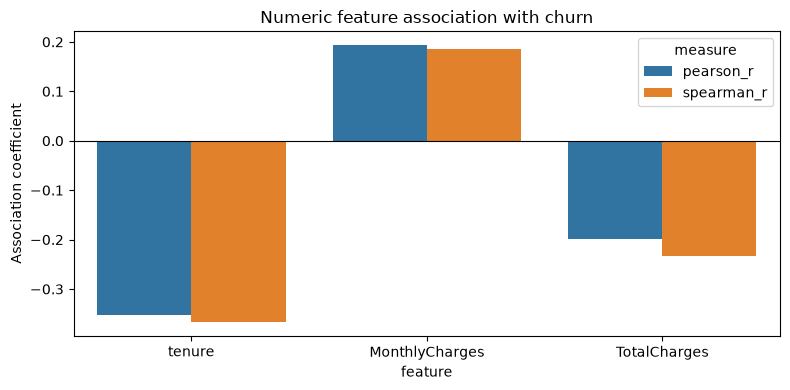

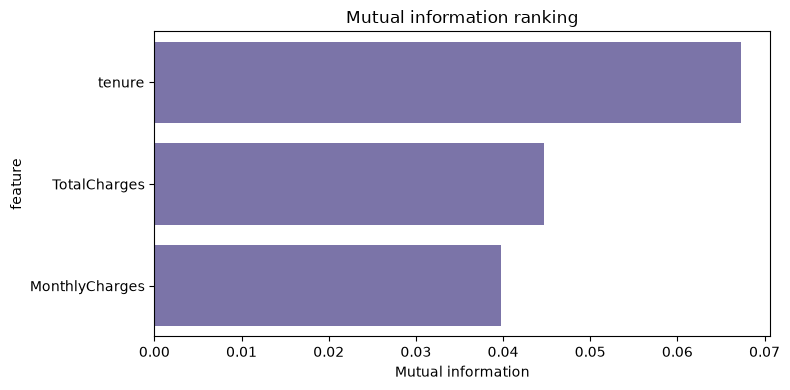

In [10]:
# Visual comparison of Pearson and Spearman coefficients.
correlation_plot = correlation_with_target.melt(id_vars="feature", value_vars=["pearson_r", "spearman_r"], var_name="measure", value_name="coefficient")
plt.figure(figsize=(8, 4))
sns.barplot(data=correlation_plot, x="feature", y="coefficient", hue="measure")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Numeric feature association with churn")
plt.ylabel("Association coefficient")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=mutual_information_table, x="mutual_information", y="feature", color="#756bb1")
plt.title("Mutual information ranking")
plt.xlabel("Mutual information")
plt.tight_layout()
plt.show()

## Outcome and usefulness

### Outcome
- Normality is assessed with Shapiro-Wilk, Anderson-Darling, D'Agostino K-squared, skewness, kurtosis, and Q-Q plots. The numeric features are not normally distributed at conventional significance levels, especially in this large sample.
- The notebook compares churned and retained groups with Welch's t-test and Mann-Whitney U. The non-parametric test is an important companion because distributional assumptions are not fully satisfied.
- Numeric effect sizes show that `tenure` has the strongest standardized difference, while `MonthlyCharges` and `TotalCharges` show moderate differences. P-values are reported together with Cohen's $d$ and rank-biserial correlation.
- Categorical associations are evaluated with chi-square independence, Cramer's V, and Fisher's exact fallback for suitable small 2x2 tables. Stronger observed associations occur for variables such as `Contract`, `TechSupport`, `InternetService`, and `PaymentMethod`, while `gender` is comparatively weak in this dataset.
- Benjamini-Hochberg FDR correction adjusts the planned collection of p-values so that significance is not interpreted from dozens of uncorrected tests.
- Pearson, Spearman, and Kendall statistics compare linear and rank-based association. Mutual information ranks comparative dependency beyond a single correlation coefficient.

### Why this is useful
- It prevents a p-value-only analysis. With thousands of customers, very small p-values can occur for practically small effects, so effect size is required for interpretation.
- It makes test choice defensible: tests are selected based on variable type, distribution, sample size, and research question.
- FDR correction reduces the risk of declaring spurious discoveries when many features are tested.
- The results prioritize variables for feature engineering, interaction analysis, and model interpretation without claiming that they cause churn.
- Comparing Pearson, Spearman, Kendall, and mutual information helps identify associations that may not be adequately described by one linear coefficient.
- The statistical results provide an evidence layer that complements, but does not replace, predictive validation.

### Modeling hand-off
Use statistically supported features as candidates, not automatic deletions. Keep the untouched test set out of target-dependent selection, and compare statistical evidence with validation performance, permutation importance, stability, calibration, and business relevance.